<a href="https://colab.research.google.com/github/Geesara-Abenayaka/imdb-movie-rating-prediction/blob/main/ML_PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Imports and Data Preparation

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted')

# 1. Load Data
df = pd.read_csv("/content/drive/MyDrive/ML/IMDB-Movie-Data.csv")

# Clean Target Variable
df['Rating'] = pd.to_numeric(df['Rating'], errors='coerce')
df.dropna(subset=['Rating'], inplace=True)
df.reset_index(drop=True, inplace=True)

print(f"Initial Shape: {df.shape}")

Initial Shape: (1000, 12)


Feature Engineering

In [ ]:
# 1. Release Year & Period Feature

df['Year'] = pd.to_numeric(df['Year'], errors='coerce')
df['Years_Since_Release'] = df['Year'].max() - df['Year']

# 2. Genre Processing (Multi-label Binarization)
all_genres = [
    g.strip()
    for sublist in df['Genre'].dropna().str.split(',')
    for g in sublist
]
top_genres = [g for g, _ in Counter(all_genres).most_common(10)]

for genre in top_genres:
    df[f'genre_{genre}'] = df['Genre'].str.contains(genre, na=False).astype(int)

df['genre_count'] = df['Genre'].str.split(',').apply(lambda x: len(x) if isinstance(x, list) else 1)

# 3. Clean Runtime
df['Runtime (Minutes)'] = pd.to_numeric(df['Runtime (Minutes)'], errors='coerce')
df['Runtime (Minutes)'].fillna(df['Runtime (Minutes)'].median(), inplace=True)

# 4. Out-of-Fold / Historical Director Prior
director_counts = df['Director'].value_counts()
director_means = df.groupby('Director')['Rating'].mean()
global_mean = df['Rating'].mean()

# Smoothing parameter (Empirical Bayes weighting)
m = 3
smoothed_director_score = (director_counts * director_means + m * global_mean) / (director_counts + m)
df['director_historical_score'] = df['Director'].map(smoothed_director_score).fillna(global_mean)

print("Pre-release feature engineering completed.")

Pre-release feature engineering completed.


Feature Matrix & Train-Test Split

In [ ]:
genre_cols = [f'genre_{g}' for g in top_genres]

# Selecting only Pre-release features
feature_cols = [
    'Runtime (Minutes)',
    'Years_Since_Release',
    'genre_count',
    'director_historical_score'
] + genre_cols

X = df[feature_cols].copy()
y = df['Rating'].copy()

# 80% Train, 20% Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Features: {feature_cols}")
print(f"Train Shape: {X_train.shape}, Test Shape: {X_test.shape}")

Features: ['Runtime (Minutes)', 'Years_Since_Release', 'genre_count', 'director_historical_score', 'genre_Drama', 'genre_Action', 'genre_Comedy', 'genre_Adventure', 'genre_Thriller', 'genre_Crime', 'genre_Romance', 'genre_Sci-Fi', 'genre_Horror', 'genre_Mystery']
Train Shape: (800, 14), Test Shape: (200, 14)


Preprocessing Pipeline Setup

In [ ]:
numeric_scale_cols = [
    'Runtime (Minutes)',
    'Years_Since_Release',
    'genre_count',
    'director_historical_score'
]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_scale_cols),
        ('pass', 'passthrough', genre_cols)
    ]
)

Model Training & Evaluation Function

In [ ]:
results_summary = []

def evaluate_model(name, model_pipeline, X_tr, X_te, y_tr, y_te):
    # Fit Pipeline
    model_pipeline.fit(X_tr, y_tr)
    preds = model_pipeline.predict(X_te)

    # Metrics
    rmse = np.sqrt(mean_squared_error(y_te, preds))
    mae = mean_absolute_error(y_te, preds)
    r2 = r2_score(y_te, preds)

    # 5-Fold Cross Validation
    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    cv_scores = cross_val_score(model_pipeline, X_tr, y_tr, cv=cv, scoring='neg_root_mean_squared_error')
    cv_rmse = -cv_scores.mean()

    print(f"\n{'='*35}")
    print(f"Model: {name}")
    print(f"Test RMSE : {rmse:.4f}")
    print(f"Test MAE  : {mae:.4f}")
    print(f"Test R²   : {r2:.4f}")
    print(f"CV RMSE   : {cv_rmse:.4f} (±{cv_scores.std():.4f})")
    print(f"{'='*35}")

    results_summary.append({
        'Model': name,
        'RMSE': rmse,
        'MAE': mae,
        'R2': r2,
        'CV_RMSE': cv_rmse
    })
    return preds

Running Models (Ridge, Random Forest, XGBoost)

In [ ]:
# 1. Ridge Regression Pipeline
ridge_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', Ridge(alpha=10.0))
])
ridge_preds = evaluate_model('Ridge Regression', ridge_pipe, X_train, X_test, y_train, y_test)

# 2. Random Forest Pipeline
rf_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=200, max_depth=6, random_state=42))
])
rf_preds = evaluate_model('Random Forest', rf_pipe, X_train, X_test, y_train, y_test)

# 3. XGBoost Pipeline
xgb_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', XGBRegressor(
        n_estimators=150,
        learning_rate=0.03,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        verbosity=0
    ))
])
xgb_preds = evaluate_model('XGBoost', xgb_pipe, X_train, X_test, y_train, y_test)


Model: Ridge Regression
Test RMSE : 0.5137
Test MAE  : 0.3852
Test R²   : 0.7247
CV RMSE   : 0.4869 (±0.0292)

Model: Random Forest
Test RMSE : 0.4906
Test MAE  : 0.3373
Test R²   : 0.7489
CV RMSE   : 0.4578 (±0.0356)

Model: XGBoost
Test RMSE : 0.4829
Test MAE  : 0.3390
Test R²   : 0.7567
CV RMSE   : 0.4633 (±0.0345)


Feature Importance & Residual Analysis

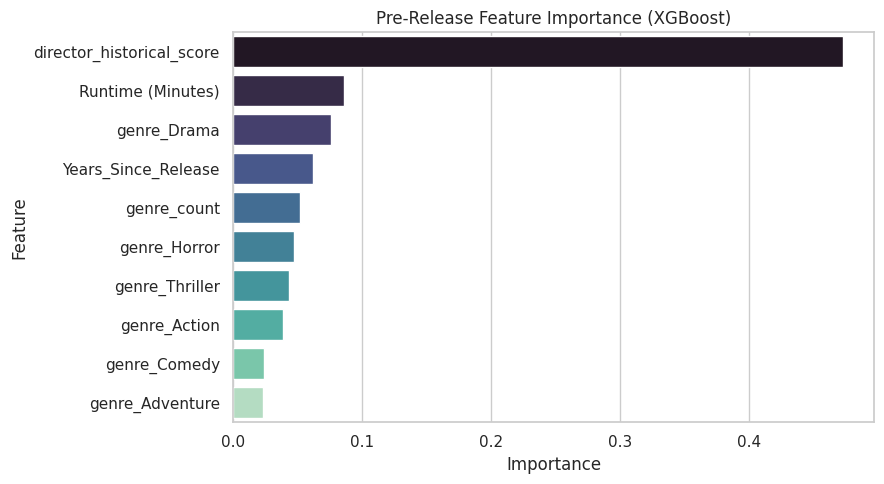

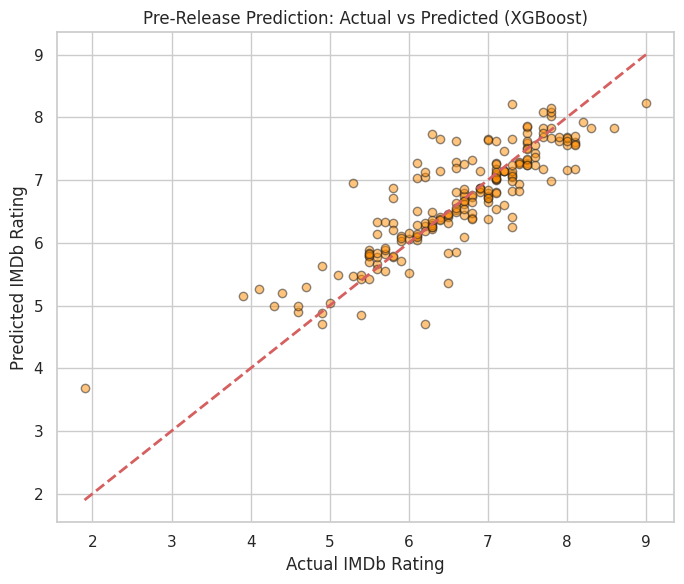


Final Model Leaderboard:
              Model      RMSE       MAE        R2   CV_RMSE
1           XGBoost  0.482944  0.338950  0.756683  0.463307
2     Random Forest  0.490632  0.337314  0.748875  0.457790
3  Ridge Regression  0.513724  0.385189  0.724679  0.486863


In [ ]:
# Extract Feature Names after preprocessing
encoded_features = numeric_scale_cols + genre_cols

# XGBoost Feature Importance
xgb_fitted = xgb_pipe.named_steps['regressor']
importance_df = pd.DataFrame({
    'Feature': encoded_features,
    'Importance': xgb_fitted.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(data=importance_df.head(10), x='Importance', y='Feature', palette='mako')
plt.title('Pre-Release Feature Importance (XGBoost)')
plt.tight_layout()
plt.show()

# Actual vs Predicted Plot
plt.figure(figsize=(7, 6))
plt.scatter(y_test, xgb_preds, alpha=0.5, color='darkorange', edgecolors='k')
lims = [min(y_test.min(), xgb_preds.min()), max(y_test.max(), xgb_preds.max())]
plt.plot(lims, lims, 'r--', linewidth=2)
plt.xlabel('Actual IMDb Rating')
plt.ylabel('Predicted IMDb Rating')
plt.title('Pre-Release Prediction: Actual vs Predicted (XGBoost)')
plt.tight_layout()
plt.show()

# Model Comparison Table
comparison_df = pd.DataFrame(results_summary).sort_values('RMSE').reset_index(drop=True)
comparison_df.index += 1
print("\nFinal Model Leaderboard:")
print(comparison_df)

In [ ]:
def predict_movie_rating(runtime, release_year, director_name, genres_list):

    # 1. Years since release
    max_year = df['Year'].max()
    years_since = max_year - release_year

    # 2. Director Historical Score
    dir_score = smoothed_director_score.get(director_name, global_mean)

    # 3. Input Data dictionary
    input_data = {
        'Runtime (Minutes)': [runtime],
        'Years_Since_Release': [years_since],
        'genre_count': [len(genres_list)],
        'director_historical_score': [dir_score]
    }
    # 4. assingning One-Hot Encoding(0 or 1) to top 10 genres
    for g in top_genres:
        input_data[f'genre_{g}'] = [1 if g in genres_list else 0]

    # Converting into a Dataframe
    new_movie_df = pd.DataFrame(input_data)

    # 5. Predicting using the XGBoost Pipeline
    predicted_rating = xgb_pipe.predict(new_movie_df)[0]

    return round(float(predicted_rating), 2)

In [ ]:
# Predicting the movie by calling the Function
predicted_rate = predict_movie_rating(
    runtime=150,
    release_year=2024,
    director_name="Christopher Nolan",
    genres_list=["Action", "Sci-Fi", "Drama"]
)

print(f"⭐ Predicted IMDb Rating: {predicted_rate} / 10")

# Comparing the metrics of the data set to get the Context
print("\n--- Context & Statistics ---")
print(f"Dataset Mean Rating     : {df['Rating'].mean():.2f} / 10")
print(f"Dataset 90th Percentile : {df['Rating'].quantile(0.90):.2f} / 10")
print(f"Dataset Max Rating      : {df['Rating'].max():.2f} / 10")

# Historical rating of Christopher Nolan
nolan_movies = df[df['Director'] == 'Christopher Nolan']
if not nolan_movies.empty:
    print(f"Nolan's Average in Data : {nolan_movies['Rating'].mean():.2f} / 10 (Based on {len(nolan_movies)} movies)")
else:
    print("Christopher Nolan is a new director in this dataset, so global priors were used.")

⭐ Predicted IMDb Rating: 8.23 / 10

--- Context & Statistics ---
Dataset Mean Rating     : 6.72 / 10
Dataset 90th Percentile : 7.90 / 10
Dataset Max Rating      : 9.00 / 10
Nolan's Average in Data : 8.68 / 10 (Based on 5 movies)
